# AI651 PA3 - LargeST-SD spatio-temporal forecasting

## Q3 - data extraction, resampling, graph

In [1]:
# %% ===================== Q3 CELL 1: setup + inspect the raw files =====================
import os, gc, time
import numpy as np, pandas as pd, h5py
import matplotlib.pyplot as plt
try:
    import hdf5plugin
except ImportError:
    pass

DATA_DIR = r"./data/largest"     # <-- folder containing ca_meta.csv, ca_rn_adj.npy, ca_his_raw_2020.h5, ca_his_raw_2021.h5
OUT_DIR, FIG_DIR = "outputs", "figs"
os.makedirs(OUT_DIR, exist_ok=True); os.makedirs(FIG_DIR, exist_ok=True)
YEARS, N_EXPECTED, SD_DISTRICT = [2020, 2021], 716, 11

for f in sorted(os.listdir(DATA_DIR)):
    print(f"{f:28s} {os.path.getsize(os.path.join(DATA_DIR, f))/1e6:10.1f} MB")
meta = pd.read_csv(os.path.join(DATA_DIR, "ca_meta.csv"))
print(meta.shape, meta.columns.tolist()); print(meta.head(3))
with h5py.File(os.path.join(DATA_DIR, f"ca_his_raw_{YEARS[0]}.h5"), "r") as f:
    f.visititems(lambda name, obj: print("  ", name, getattr(obj, "shape", ""), getattr(obj, "dtype", "")))

ca_his_raw_2020.h5               7253.1 MB
ca_his_raw_2021.h5               7233.3 MB
ca_meta.csv                         0.6 MB
ca_rn_adj.npy                     591.7 MB
(8600, 10) ['ID', 'Lat', 'Lng', 'District', 'County', 'Fwy', 'Lanes', 'Type', 'Direction', 'ID2']
       ID        Lat         Lng  District      County   Fwy  Lanes      Type  \
0  317802  38.389811 -121.479587         3  Sacramento  I5-N      2  Mainline   
1  312134  38.412564 -121.484319         3  Sacramento  I5-N      2  Mainline   
2  312133  38.428630 -121.487657         3  Sacramento  I5-N      3  Mainline   

  Direction  ID2  
0         N    0  
1         N    1  
2         N    2  
   t  
   t/axis0 (8600,) |S9
   t/axis1 (105408,) int64
   t/block0_items (8600,) |S9
   t/block0_values (105408, 8600) float64


In [2]:
# %% ===================== Q3 CELL 2: select San Diego sensors =====================
sd_pos = np.where(meta["District"].values == SD_DISTRICT)[0]
sd_meta = meta.iloc[sd_pos].reset_index(drop=True)
sd_ids = sd_meta["ID"].astype(str).values
if "ID2" in meta.columns:
    print("ID2 == row position:", np.array_equal(meta["ID2"].values[sd_pos], sd_pos))
print("SD sensors:", len(sd_ids)); assert len(sd_ids) == N_EXPECTED

ID2 == row position: True
SD sensors: 716


In [3]:
# %% ===================== Q3 CELL 3: load SD columns for 2020-2021 =====================
def load_year_sd(path, ids, chunk=4096):
    try:
        with h5py.File(path, "r") as f:
            g = f[list(f.keys())[0]]
            items = np.array([x.decode() if isinstance(x, bytes) else str(x) for x in g["block0_items"][:]])
            col = {c: k for k, c in enumerate(items)}
            idx = np.array([col[i] for i in ids])
            vals = g["block0_values"]
            out = np.empty((vals.shape[0], len(idx)), np.float32)
            for r in range(0, vals.shape[0], chunk):
                out[r:r + chunk] = vals[r:r + chunk][:, idx]
            raw_t = g["axis1"][:]
            kind = g["axis1"].attrs.get("kind", b"")
            kind = kind.decode() if isinstance(kind, bytes) else str(kind)
            unit = kind[kind.find("[") + 1:-1] if "[" in kind else \
                   {18: "ns", 15: "us", 12: "ms", 9: "s"}[len(str(abs(int(raw_t[0]))))-1]
            t = pd.to_datetime(raw_t, unit=unit)
        return pd.DataFrame(out, index=t, columns=ids)
    except Exception as e:
        print("h5py path failed (", e, ") -> using pandas.read_hdf")
        df = pd.read_hdf(path)
        df.columns = df.columns.astype(str)
        out = df[list(ids)].astype(np.float32); del df; gc.collect()
        return out

frames = []
for y in YEARS:
    t0 = time.time()
    df = load_year_sd(os.path.join(DATA_DIR, f"ca_his_raw_{y}.h5"), sd_ids)
    df = df[df.index.year == y]
    full = pd.date_range(f"{y}-01-01 00:00", f"{y}-12-31 23:55", freq="5min")
    print(f"{y}: raw rows {len(df)}, expected {len(full)}, missing timestamps {len(full.difference(df.index))}, {time.time()-t0:.1f}s")
    frames.append(df.reindex(full))
raw5 = pd.concat(frames); del frames; gc.collect()
print("5-min tensor:", raw5.shape, "| value range:", np.nanmin(raw5.values), np.nanmax(raw5.values))

2020: raw rows 105408, expected 105408, missing timestamps 0, 10.2s
2021: raw rows 105120, expected 105120, missing timestamps 0, 10.5s
5-min tensor: (210528, 716) | value range: 0.0 999.0


C:\Users\danis\AppData\Local\Temp\ipykernel_15752\3886808372.py:7: RuntimeWarning: Mean of empty slice
  x15 = np.where(n_obs > 0, 3 * np.nanmean(blk, axis=1), np.nan).astype(np.float32)


5-min missing: 5.07%  |  15-min slots with no data: 5.06%
15-min slots built from <3 sub-intervals: 0.02%
per-sensor missing %: min 0.01 / median 0.01 / max 100.00
sensors missing > 50% of the time: 43
  2020: missing 4.09%, sensors with no data at all: 19
  2021: missing 6.03%, sensors with no data at all: 43
exact zeros among observed values: 0.146%


C:\Users\danis\AppData\Local\Temp\ipykernel_15752\3886808372.py:22: RuntimeWarning: Mean of empty slice
  train_mean = np.nanmean(np.where(mask[yr == 2020], x15[yr == 2020], np.nan), axis=0)


15-min tensor X: (70176, 716) (T x N); any NaN left: False


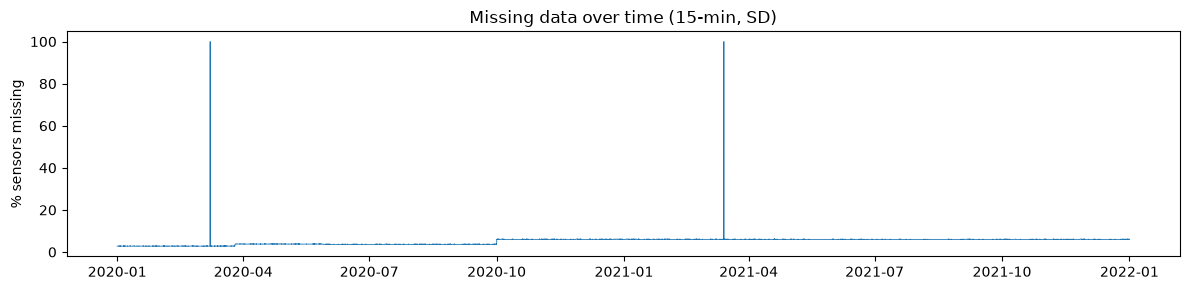

In [4]:
# %% ===================== Q3 CELL 4: resample to 15 min + missing values =====================
v5 = raw5.values.astype(np.float32)
T5, N = v5.shape
blk = v5.reshape(T5 // 3, 3, N)
n_obs = np.sum(~np.isnan(blk), axis=1)
with np.errstate(invalid="ignore"):
    x15 = np.where(n_obs > 0, 3 * np.nanmean(blk, axis=1), np.nan).astype(np.float32)
times = raw5.index[::3]
mask = ~np.isnan(x15)

print(f"5-min missing: {np.isnan(v5).mean()*100:.2f}%  |  15-min slots with no data: {(~mask).mean()*100:.2f}%")
print(f"15-min slots built from <3 sub-intervals: {((n_obs>0)&(n_obs<3)).mean()*100:.2f}%")
miss_sensor = 1 - mask.mean(0)
print("per-sensor missing %: min {:.2f} / median {:.2f} / max {:.2f}".format(*(np.percentile(miss_sensor, [0,50,100])*100)))
print("sensors missing > 50% of the time:", int((miss_sensor > .5).sum()))
yr = times.year.values
for y in YEARS:
    print(f"  {y}: missing {(~mask[yr==y]).mean()*100:.2f}%, sensors with no data at all: {int((mask[yr==y].sum(0)==0).sum())}")
print("exact zeros among observed values: {:.3f}%".format((x15[mask] == 0).mean()*100))

X = pd.DataFrame(x15).ffill().bfill().to_numpy(copy=True)
train_mean = np.nanmean(np.where(mask[yr == 2020], x15[yr == 2020], np.nan), axis=0)
still = np.isnan(X)
if still.any():
    X[still] = np.take(np.nan_to_num(train_mean, nan=np.nanmean(train_mean)), np.where(still)[1])
X = X.astype(np.float32)
print("15-min tensor X:", X.shape, "(T x N); any NaN left:", np.isnan(X).any())

fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(times, (~mask).mean(1) * 100, lw=.6)
ax.set_ylabel("% sensors missing"); ax.set_title("Missing data over time (15-min, SD)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/q3a_missing_over_time.png", dpi=200); plt.show()

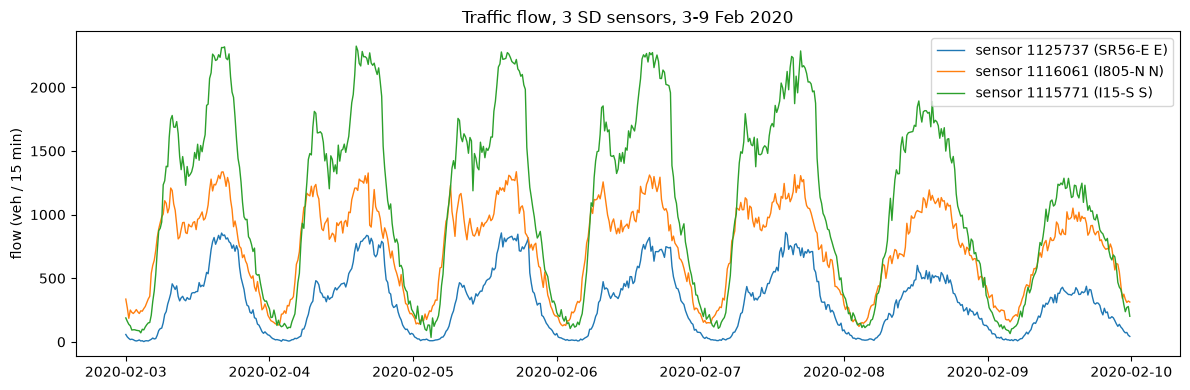

plotted sensor indices: [438, 601, 352]


In [5]:
# %% ===================== Q3 CELL 5: three sensors over one week =====================
wk = (times >= "2020-02-03") & (times < "2020-02-10")
good = np.where(mask[wk].mean(0) > 0.99)[0]
mflow = X[wk][:, good].mean(0)
pick = good[np.argsort(mflow)[[len(good)//10, len(good)//2, -1 - len(good)//10]]]
fig, ax = plt.subplots(figsize=(12, 4))
for j in pick:
    ax.plot(times[wk], X[wk, j], lw=1, label=f"sensor {sd_ids[j]} ({sd_meta.Fwy[j]} {sd_meta.Direction[j]})")
ax.set_ylabel("flow (veh / 15 min)"); ax.set_title("Traffic flow, 3 SD sensors, 3-9 Feb 2020")
ax.legend(); plt.tight_layout(); plt.savefig(f"{FIG_DIR}/q3a_three_sensors_week.png", dpi=200); plt.show()
print("plotted sensor indices:", pick.tolist())

A_SD shape: (716, 716)
nonzero entries (incl. diagonal): 18035 | diagonal nonzeros: 716
nonzero edges excluding self-loops: 17319
symmetric (exact): False | same sparsity pattern: False | max |A - A^T|: 0.9999998807907104
edge-weight range: min 0.0100 / median 0.1985 / max 1.0000


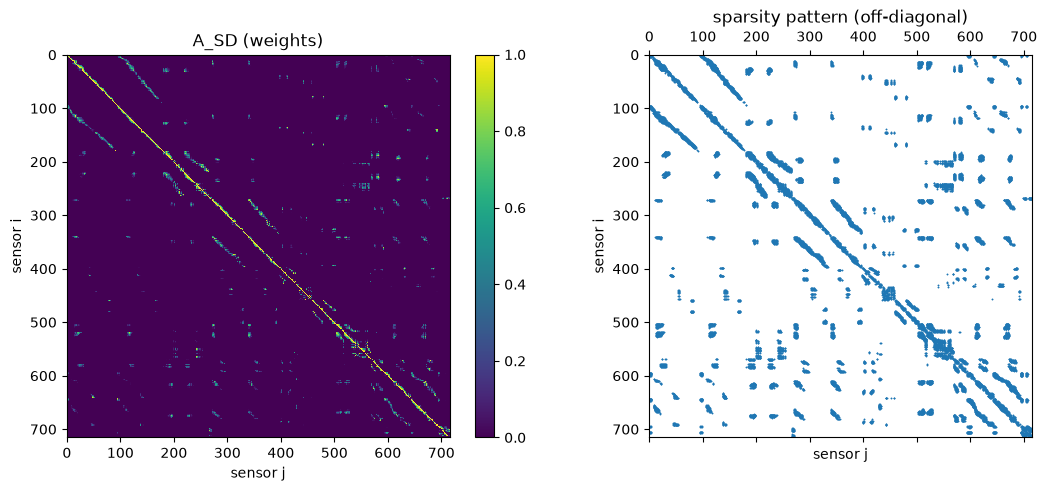

out-degree: mean 24.19, min 0, max 70, isolated nodes 3


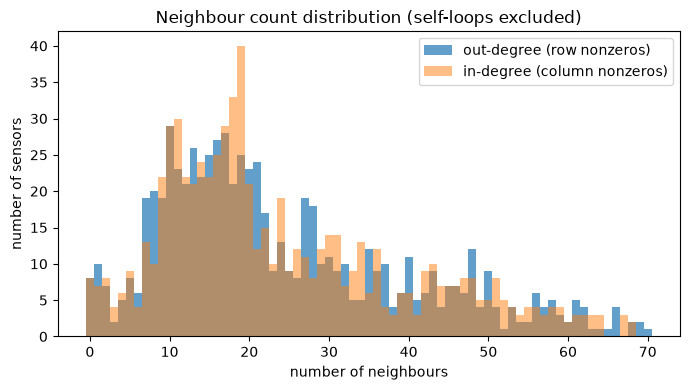

In [6]:
# %% ===================== Q3 CELL 6 (Q3b): adjacency submatrix =====================
A_ca = np.load(os.path.join(DATA_DIR, "ca_rn_adj.npy"))
A = A_ca[np.ix_(sd_pos, sd_pos)].astype(np.float32); del A_ca; gc.collect()
off = A.copy(); np.fill_diagonal(off, 0)
print("A_SD shape:", A.shape)
print("nonzero entries (incl. diagonal):", int((A != 0).sum()), "| diagonal nonzeros:", int((np.diag(A) != 0).sum()))
print("nonzero edges excluding self-loops:", int((off != 0).sum()))
print("symmetric (exact):", np.array_equal(A, A.T), "| same sparsity pattern:", np.array_equal(A != 0, A.T != 0),
      "| max |A - A^T|:", float(np.abs(A - A.T).max()))
nzv = off[off != 0]
print("edge-weight range: min {:.4f} / median {:.4f} / max {:.4f}".format(nzv.min(), np.median(nzv), nzv.max()))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
im = axes[0].imshow(A, cmap="viridis", interpolation="nearest"); axes[0].set_title("A_SD (weights)")
fig.colorbar(im, ax=axes[0], fraction=.046)
axes[1].spy(off != 0, markersize=.4); axes[1].set_title("sparsity pattern (off-diagonal)")
for a_ in axes: a_.set_xlabel("sensor j"); a_.set_ylabel("sensor i")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/q3b_adjacency.png", dpi=200); plt.show()

out_deg, in_deg = (off != 0).sum(1), (off != 0).sum(0)
print("out-degree: mean {:.2f}, min {}, max {}, isolated nodes {}".format(out_deg.mean(), out_deg.min(), out_deg.max(),
      int(((out_deg == 0) & (in_deg == 0)).sum())))
fig, ax = plt.subplots(figsize=(7, 4))
bins = np.arange(0, max(out_deg.max(), in_deg.max()) + 2) - .5
ax.hist(out_deg, bins=bins, alpha=.7, label="out-degree (row nonzeros)")
ax.hist(in_deg, bins=bins, alpha=.5, label="in-degree (column nonzeros)")
ax.set_xlabel("number of neighbours"); ax.set_ylabel("number of sensors"); ax.legend()
ax.set_title("Neighbour count distribution (self-loops excluded)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/q3b_degree_hist.png", dpi=200); plt.show()

selected sensor: idx 33, ID 1126411, I5-N N, (32.7707, -117.2067)
1-hop neighbours (20): ['1114805', '1114035', '1108547', '1118707', '1117871', '1108615', '1117818', '1126426', '1114806', '1108711', '1108693', '1111514', '1113486', '1115356', '1115413', '1115432', '1115438', '1116574', '1115528', '1115517']
<=2-hop neighbours (73), new at hop 2 (53): ['1117748', '1113976', '1117741', '1108603', '1117835', '1117717', '1118078', '1108611', '1108613', '1114050', '1108617', '1118496', '1118521', '1108665', '1117683', '1108417', '1117734', '1108605', '1118702', '1108609', '1108728', '1114540', '1111551', '1115420', '1115426', '1111566', '1115444', '1116783', '1114546', '1115555', '1115565', '1111552', '1116165', '1115548', '1111540', '1115572', '1121818', '1114450', '1114457', '1113279', '1111539', '1108331', '1111520', '1121821', '1114463', '1111509', '1121288', '1116112', '1113460', '1108572', '1115921', '1108391', '1115929']
   1114805: A[i,j]=0.953, I5-N N
   1114035: A[i,j]=0.824, I5-

c:\Users\danis\Documents\LUMS\DL for Time, Space and Graphs\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:587: RuntimeWarning: Mean of empty slice
  avg = a.mean(axis, **keepdims_kw)
c:\Users\danis\Documents\LUMS\DL for Time, Space and Graphs\.venv\Lib\site-packages\numpy\_core\_methods.py:134: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(
c:\Users\danis\Documents\LUMS\DL for Time, Space and Graphs\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:3028: RuntimeWarning: Degrees of freedom <= 0 for slice
  c = cov(x, y, rowvar, dtype=dtype)
c:\Users\danis\Documents\LUMS\DL for Time, Space and Graphs\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:2901: RuntimeWarning: divide by zero encountered in divide
  c *= np.true_divide(1, fact)
c:\Users\danis\Documents\LUMS\DL for Time, Space and Graphs\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:2901: RuntimeWarning: invalid value encountered in multiply
  c *= np.true_divide(1

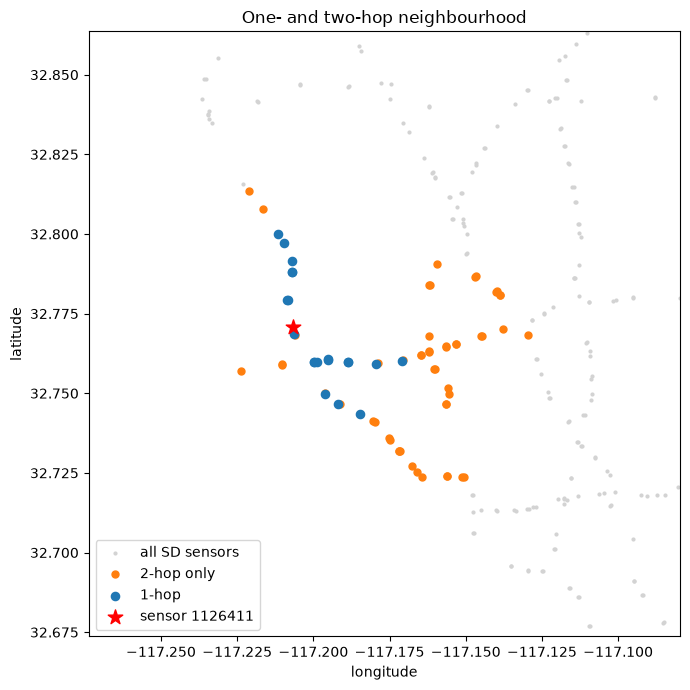

In [7]:
# %% ===================== Q3 CELL 7 (Q3c): one- and two-hop neighbourhoods =====================
B = (off != 0).astype(int)
i0 = int(np.argsort(out_deg)[len(out_deg) // 2])
hop1 = set(np.where(B[i0])[0])
hop2 = set(np.where((B + B @ B)[i0] > 0)[0]) - {i0}
print(f"selected sensor: idx {i0}, ID {sd_ids[i0]}, {sd_meta.Fwy[i0]} {sd_meta.Direction[i0]}, "
      f"({sd_meta.Lat[i0]:.4f}, {sd_meta.Lng[i0]:.4f})")
print(f"1-hop neighbours ({len(hop1)}):", [sd_ids[j] for j in sorted(hop1)])
print(f"<=2-hop neighbours ({len(hop2)}), new at hop 2 ({len(hop2-hop1)}):", [sd_ids[j] for j in sorted(hop2-hop1)])
for j in sorted(hop1):
    print(f"   {sd_ids[j]}: A[i,j]={off[i0,j]:.3f}, {sd_meta.Fwy[j]} {sd_meta.Direction[j]}")
obs = mask[:, [i0] + sorted(hop1)].all(1)
cc = np.corrcoef(X[obs][:, [i0] + sorted(hop1)].T)[0, 1:]
rand = np.random.default_rng(0).choice(N, 20, replace=False)
cr = np.corrcoef(X[:, np.r_[i0, rand]].T)[0, 1:]
print("flow correlation with 1-hop neighbours:", np.round(cc, 3), "| with 20 random sensors (mean):", round(cr.mean(), 3))

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(sd_meta.Lng, sd_meta.Lat, s=4, c="lightgrey", label="all SD sensors")
h2 = sorted(hop2 - hop1)
ax.scatter(sd_meta.Lng[h2], sd_meta.Lat[h2], s=25, c="tab:orange", label="2-hop only")
ax.scatter(sd_meta.Lng[sorted(hop1)], sd_meta.Lat[sorted(hop1)], s=35, c="tab:blue", label="1-hop")
ax.scatter(sd_meta.Lng[i0], sd_meta.Lat[i0], s=120, c="red", marker="*", label=f"sensor {sd_ids[i0]}")
nb = [i0] + sorted(hop2); pad = .05
ax.set_xlim(sd_meta.Lng[nb].min() - pad, sd_meta.Lng[nb].max() + pad)
ax.set_ylim(sd_meta.Lat[nb].min() - pad, sd_meta.Lat[nb].max() + pad)
ax.set_xlabel("longitude"); ax.set_ylabel("latitude"); ax.legend(); ax.set_title("One- and two-hop neighbourhood")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/q3c_neighbourhood_map.png", dpi=200); plt.show()

In [8]:
# %% ===================== Q3 CELL 8: save for Q4-Q6 =====================
np.savez_compressed(f"{OUT_DIR}/sd_15min.npz", X=X, mask=mask,
                    times=times.values.astype("datetime64[ns]").astype(np.int64),
                    A=A, ids=sd_ids, lat=sd_meta.Lat.values, lng=sd_meta.Lng.values)
print("saved", f"{OUT_DIR}/sd_15min.npz")

saved outputs/sd_15min.npz


In [11]:
# %% ===================== Q3 CELL 9: fixed correlations, k-hop growth, 999 check =====================
rng = np.random.default_rng(0)

def corr_obs(a, b, min_obs=1000):
    m = mask[:, a] & mask[:, b]
    return np.corrcoef(X[m, a], X[m, b])[0, 1] if m.sum() >= min_obs else np.nan

ok_sensors = np.where(mask.mean(0) > 0.5)[0]
c1 = np.array([corr_obs(i0, j) for j in sorted(hop1)])
c2 = np.array([corr_obs(i0, j) for j in sorted(hop2 - hop1)])
cr = np.array([corr_obs(i0, j) for j in rng.choice(ok_sensors[ok_sensors != i0], 50, replace=False)])
print(f"flow correlation with sensor {sd_ids[i0]}:")
print(f"  1-hop  : mean {np.nanmean(c1):.3f}  (n={np.isfinite(c1).sum()})")
print(f"  2-hop  : mean {np.nanmean(c2):.3f}  (n={np.isfinite(c2).sum()})")
print(f"  random : mean {np.nanmean(cr):.3f}  (n={np.isfinite(cr).sum()})")
print("  per 1-hop neighbour:", np.round(c1, 3))

Bn = (off != 0).astype(np.int32); reach = np.eye(N, dtype=bool)
for k in range(1, 7):
    reach = reach | ((reach.astype(np.int32) @ Bn) > 0)
    print(f"  <= {k}-hop: mean reachable sensors {reach.sum(1).mean() - 1:7.1f}  "
          f"({(reach.sum(1).mean() - 1) / (N - 1) * 100:5.1f}% of the network)")

try:
    v = raw5.values
    print("raw 5-min values == 999:", int((v == 999).sum()), "| >= 900:", int((v >= 900).sum()),
          "| 99.99th percentile:", np.nanpercentile(v, 99.99))
except NameError:
    print("15-min values >= 2997 (=3*999):", int((X[mask] >= 2997).sum()), "| 99.99th pct:", np.percentile(X[mask], 99.99))

flow correlation with sensor 1126411:
  1-hop  : mean 0.913  (n=19)
  2-hop  : mean 0.915  (n=50)
  random : mean 0.896  (n=50)
  per 1-hop neighbour: [0.873 0.985 0.991 0.978 0.928 0.924 0.931 0.919 0.925 0.922 0.896 0.809
 0.873 0.871 0.877 0.877 0.873 0.918   nan 0.969]
  <= 1-hop: mean reachable sensors    24.2  (  3.4% of the network)
  <= 2-hop: mean reachable sensors    66.9  (  9.4% of the network)
  <= 3-hop: mean reachable sensors   116.0  ( 16.2% of the network)
  <= 4-hop: mean reachable sensors   171.6  ( 24.0% of the network)
  <= 5-hop: mean reachable sensors   230.2  ( 32.2% of the network)
  <= 6-hop: mean reachable sensors   288.5  ( 40.4% of the network)
raw 5-min values == 999: 155 | >= 900: 33148 | 99.99th percentile: 938.0


## Q4 / Q5 - windows, models, training

In [12]:
# %% ===================== Q4 CELL 1: data, splits, windows, normalisation =====================
import os, json, time, random
import torch, torch.nn as nn, torch.nn.functional as F

OUT_DIR, FIG_DIR = "outputs", "figs"
os.makedirs(OUT_DIR, exist_ok=True); os.makedirs(FIG_DIR, exist_ok=True)
SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
T_IN, HORIZON = 8, 4

def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False
set_seed()

d = np.load(f"{OUT_DIR}/sd_15min.npz", allow_pickle=True)
X_np, M_np, A_np = d["X"].astype(np.float32), d["mask"], d["A"].astype(np.float32)
times = pd.to_datetime(d["times"]); ids = d["ids"]; lat, lng = d["lat"], d["lng"]
T, N = X_np.shape
print("X:", X_np.shape, "| device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")

split_masks = {"train": (times >= "2020-01-01") & (times < "2021-01-01"),
               "val":   (times >= "2021-01-01") & (times < "2021-04-01"),
               "test":  (times >= "2021-04-01") & (times < "2022-01-01")}

def window_index(split):
    """Prediction times t with x_{t-7..t} and x_{t+1..t+4} all inside the split (no boundary crossing)."""
    pos = np.where(split_masks[split])[0]
    lo, hi = pos.min(), pos.max()
    return np.arange(lo + T_IN - 1, hi - HORIZON + 1)

idx = {s: window_index(s) for s in split_masks}
for s in idx:
    print(f"{s:5s}: {split_masks[s].sum():6d} steps, {len(idx[s]):6d} windows, "
          f"{times[idx[s][0] - T_IN + 1]} -> {times[idx[s][-1] + HORIZON]}")

tr = split_masks["train"]
MU = float(X_np[tr][M_np[tr]].mean()); SD = float(X_np[tr][M_np[tr]].std())
print(f"train mean {MU:.2f}, train std {SD:.2f} (veh / 15 min)")

Xg = torch.tensor((X_np - MU) / SD, device=DEVICE)
Mg = torch.tensor(M_np, device=DEVICE)
OFF_IN = torch.arange(-T_IN + 1, 1, device=DEVICE)
OFF_OUT = torch.arange(1, HORIZON + 1, device=DEVICE)

def get_batch(t_idx):
    t = torch.as_tensor(t_idx, device=DEVICE)
    return Xg[t[:, None] + OFF_IN], Xg[t[:, None] + OFF_OUT], Mg[t[:, None] + OFF_OUT]   # x (B,8,N), y (B,4,N), m (B,4,N)

X: (70176, 716) | device: cuda NVIDIA GeForce RTX 2060
train:  35136 steps,  35125 windows, 2020-01-01 00:00:00 -> 2020-12-31 23:45:00
val  :   8640 steps,   8629 windows, 2021-01-01 00:00:00 -> 2021-03-31 23:45:00
test :  26400 steps,  26389 windows, 2021-04-01 00:00:00 -> 2021-12-31 23:45:00
train mean 607.39, train std 483.77 (veh / 15 min)


In [33]:
# %% ===================== Q4 CELL 2: model components =====================
class TemporalEncoder(nn.Module):
    """Per-sensor temporal CNN, shared by all sensors: (B, 8, N) -> Z (B, N, d)."""
    def __init__(self, d=32, k=3):
        super().__init__()
        self.conv1 = nn.Conv1d(1, d, k)                      # length 8 -> 6
        self.conv2 = nn.Conv1d(d, d, k, dilation=2)          # length 6 -> 2 (covers all 8 steps)
        self.proj = nn.Linear(2 * d, d)
    def forward(self, x):
        B, T_, N_ = x.shape
        h = x.permute(0, 2, 1).reshape(B * N_, 1, T_)
        h = F.relu(self.conv1(h)); h = F.relu(self.conv2(h))
        return F.relu(self.proj(h.flatten(1))).view(B, N_, -1)

class GraphConv(nn.Module):
    """H = ReLU(A_hat Z W_g); multiplication over the node dimension, per batch item."""
    def __init__(self, d):
        super().__init__(); self.W = nn.Linear(d, d, bias=False)
    def forward(self, Z, A_hat):
        return F.relu(torch.einsum("nm,bmd->bnd", A_hat, self.W(Z)))

class Head(nn.Module):
    def __init__(self, d, horizon=HORIZON):
        super().__init__(); self.net = nn.Sequential(nn.Linear(d, d), nn.ReLU(), nn.Linear(d, horizon))
    def forward(self, H):                                    # (B, N, d) -> (B, 4, N)
        return self.net(H).permute(0, 2, 1)

def row_normalise(A):
    """Directed random-walk normalisation A_hat = D_out^{-1} (A + I); every row sums to 1."""
    A = A + np.eye(A.shape[0], dtype=A.dtype)
    return (A / A.sum(1, keepdims=True)).astype(np.float32)

class STModel(nn.Module):
    """graph in {'none', 'fixed', 'adaptive', 'hybrid'}; identical encoder + head in every variant."""
    def __init__(self, N, graph="fixed", A_fixed=None, d=32, emb_dim=10, topk=None, alpha=None):
        super().__init__()
        self.graph, self.topk = graph, topk
        self.encoder, self.head = TemporalEncoder(d), Head(d)
        if graph != "none":
            self.gconv = GraphConv(d)
        if graph in ("fixed", "hybrid"):
            self.register_buffer("A_fixed", torch.tensor(A_fixed))       # buffer -> never updated
        if graph in ("adaptive", "hybrid"):
            self.E1 = nn.Parameter(torch.randn(N, emb_dim))              # random init, learned by backprop
            self.E2 = nn.Parameter(torch.randn(N, emb_dim))
        if graph == "hybrid":
            self.alpha_fixed = alpha
            self.alpha_logit = nn.Parameter(torch.zeros(()))             # sigmoid(0) = 0.5 at start

    def adaptive_adj(self):
        logits = F.relu(self.E1 @ self.E2.T)
        if self.topk is not None:                                        # optional: sparsify BEFORE softmax
            v, j = logits.topk(self.topk, dim=1)
            logits = torch.full_like(logits, float("-inf")).scatter(1, j, v)
        return torch.softmax(logits, dim=1)                              # row-wise

    def alpha(self):
        return torch.tensor(self.alpha_fixed) if self.alpha_fixed is not None else torch.sigmoid(self.alpha_logit)

    def adjacency(self):
        if self.graph == "fixed":    return self.A_fixed
        if self.graph == "adaptive": return self.adaptive_adj()
        a = self.alpha()
        return a * self.A_fixed + (1 - a) * self.adaptive_adj()

    def forward(self, x):
        Z = self.encoder(x)
        H = Z if self.graph == "none" else Z + self.gconv(Z, self.adjacency())   # residual
        return self.head(H)

A_hat_fixed = row_normalise(A_np)
for g in ["none", "fixed", "adaptive", "hybrid"]:
    m = STModel(N, g, A_hat_fixed)
    print(f"{g:9s} trainable params: {sum(p.numel() for p in m.parameters() if p.requires_grad):,}")

yr_ = times.year.values; dead_ = M_np[yr_ == 2020].mean(0) < 0.05
print("dead-in-2020 sensors observed in 2021 (%):", np.round(M_np[yr_ == 2021][:, dead_].mean(0) * 100, 1))
print("their (constant) 2020 input values:", np.unique(np.round(X_np[yr_ == 2020][:, dead_][0], 1)))

none      trainable params: 6,500
fixed     trainable params: 7,524
adaptive  trainable params: 21,844
hybrid    trainable params: 21,845
dead-in-2020 sensors observed in 2021 (%): [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
their (constant) 2020 input values: [604.7]


In [23]:
# %% ===================== Q4 CELL 3: training + evaluation =====================
CFG = dict(d=32, emb_dim=10, batch_size=64, lr=1e-3, weight_decay=1e-4, max_epochs=40, patience=6,
           grad_clip=5.0, loss="masked MAE", seed=SEED)
PLOT_SENSORS = [438, 601, 352]                             # the three sensors from Q3(a)

def masked_mae(p, y, m):
    m = m.float(); return (torch.abs(p - y) * m).sum() / m.sum().clamp(min=1)

@torch.no_grad()
def evaluate(model, split, bs=256, keep=None):
    model.eval(); ae_h = torch.zeros(HORIZON, device=DEVICE); se_h = torch.zeros_like(ae_h)
    n_h = torch.zeros_like(ae_h); kept = []
    for s in range(0, len(idx[split]), bs):
        x, y, m = get_batch(idx[split][s:s + bs])
        p = model(x)
        e = (p - y) * SD                                    # original units (veh / 15 min)
        mf = m.float()
        ae_h += (e.abs() * mf).sum((0, 2)); se_h += (e**2 * mf).sum((0, 2)); n_h += mf.sum((0, 2))
        if keep is not None: kept.append((p[:, :, keep] * SD + MU).cpu().numpy())
    res = {"MAE": float(ae_h.sum() / n_h.sum()), "RMSE": float(torch.sqrt(se_h.sum() / n_h.sum())),
           "MAE_h": (ae_h / n_h).tolist(), "RMSE_h": torch.sqrt(se_h / n_h).tolist()}
    return (res, np.concatenate(kept)) if keep is not None else res

NO_DECAY = ("E1", "E2", "alpha_logit")
def make_optimizer(model):
    """Adam; no weight decay on the graph-structure parameters (L2 + Adam would shrink them to 0 -> uniform graph)."""
    decay = [p for n, p in model.named_parameters() if n not in NO_DECAY]
    no_decay = [p for n, p in model.named_parameters() if n in NO_DECAY]
    groups = [{"params": decay, "weight_decay": CFG["weight_decay"]}]
    if no_decay: groups.append({"params": no_decay, "weight_decay": 0.0})
    return torch.optim.Adam(groups, lr=CFG["lr"])

def train_model(name, graph, **kw):
    set_seed()
    model = STModel(N, graph, A_hat_fixed, d=CFG["d"], emb_dim=CFG["emb_dim"], **kw).to(DEVICE)
    opt = make_optimizer(model)
    best, best_ep, wait, hist = float("inf"), 0, 0, []
    rng = np.random.default_rng(SEED)
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    t0 = time.time()
    for ep in range(1, CFG["max_epochs"] + 1):
        model.train(); te = time.time(); losses = []
        perm = rng.permutation(idx["train"])
        for s in range(0, len(perm), CFG["batch_size"]):
            x, y, m = get_batch(perm[s:s + CFG["batch_size"]])
            loss = masked_mae(model(x), y, m)
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), CFG["grad_clip"]); opt.step()
            losses.append(loss.item())
        v = evaluate(model, "val")
        hist.append({"epoch": ep, "train_loss": float(np.mean(losses)) * SD, "val_MAE": v["MAE"], "val_RMSE": v["RMSE"],
                     "epoch_time": time.time() - te})
        extra = f" alpha={model.alpha().item():.3f}" if graph == "hybrid" else ""
        print(f"[{name}] ep {ep:2d} train MAE {hist[-1]['train_loss']:.2f} | val MAE {v['MAE']:.2f} "
              f"RMSE {v['RMSE']:.2f} | {hist[-1]['epoch_time']:.1f}s{extra}")
        if v["MAE"] < best - 1e-3:
            best, best_ep, wait = v["MAE"], ep, 0
            torch.save(model.state_dict(), f"{OUT_DIR}/{name}.pt")
        else:
            wait += 1
            if wait >= CFG["patience"]: print(f"[{name}] early stop"); break
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    train_time = time.time() - t0
    model.load_state_dict(torch.load(f"{OUT_DIR}/{name}.pt"))
    val = evaluate(model, "val"); test, test_pred = evaluate(model, "test", keep=PLOT_SENSORS)
    res = {"name": name, "graph": graph, "val": val, "test": test, "train_time_s": train_time,
           "epochs_run": len(hist), "best_epoch": best_ep, "history": hist,
           "params": sum(p.numel() for p in model.parameters() if p.requires_grad)}
    if graph == "hybrid": res["alpha"] = float(model.alpha().detach())
    json.dump(res, open(f"{OUT_DIR}/res_{name}.json", "w"), indent=1)
    np.save(f"{OUT_DIR}/pred_{name}.npy", test_pred)
    if graph in ("adaptive", "hybrid"):
        with torch.no_grad(): np.save(f"{OUT_DIR}/Aadapt_{name}.npy", model.adaptive_adj().cpu().numpy())
    print(f"[{name}] VAL MAE {val['MAE']:.2f} RMSE {val['RMSE']:.2f} | TEST MAE {test['MAE']:.2f} "
          f"RMSE {test['RMSE']:.2f} | train time {train_time:.1f}s ({len(hist)} epochs, best {best_ep})")
    return model, res

In [15]:
# %% ===================== Q4 CELL 4 (Q4b + Q5a): fixed road-distance graph =====================
model_fixed, res_fixed = train_model("stgnn_fixed", "fixed")

[stgnn_fixed] ep  1 train MAE 83.95 | val MAE 59.81 RMSE 96.61 | 8.3s
[stgnn_fixed] ep  2 train MAE 57.49 | val MAE 58.24 RMSE 94.78 | 7.2s
[stgnn_fixed] ep  3 train MAE 56.74 | val MAE 59.06 RMSE 95.02 | 7.2s
[stgnn_fixed] ep  4 train MAE 56.50 | val MAE 57.41 RMSE 93.13 | 7.2s
[stgnn_fixed] ep  5 train MAE 56.01 | val MAE 60.41 RMSE 96.80 | 7.2s
[stgnn_fixed] ep  6 train MAE 55.65 | val MAE 58.13 RMSE 93.03 | 7.2s
[stgnn_fixed] ep  7 train MAE 55.29 | val MAE 56.65 RMSE 91.67 | 7.3s
[stgnn_fixed] ep  8 train MAE 54.99 | val MAE 56.46 RMSE 91.19 | 7.3s
[stgnn_fixed] ep  9 train MAE 54.87 | val MAE 55.90 RMSE 90.46 | 7.3s
[stgnn_fixed] ep 10 train MAE 54.58 | val MAE 55.89 RMSE 90.86 | 7.3s
[stgnn_fixed] ep 11 train MAE 54.45 | val MAE 56.36 RMSE 90.74 | 7.4s
[stgnn_fixed] ep 12 train MAE 54.36 | val MAE 56.99 RMSE 91.12 | 7.5s
[stgnn_fixed] ep 13 train MAE 54.07 | val MAE 57.62 RMSE 90.53 | 7.6s
[stgnn_fixed] ep 14 train MAE 54.06 | val MAE 55.10 RMSE 89.26 | 7.6s
[stgnn_fixed] ep 15 

In [16]:
# %% ===================== Q4 CELL 5 (Q4c): temporal-only baseline =====================
model_temp, res_temp = train_model("temporal_only", "none")

[temporal_only] ep  1 train MAE 87.00 | val MAE 61.07 RMSE 98.20 | 7.1s
[temporal_only] ep  2 train MAE 59.21 | val MAE 60.06 RMSE 97.79 | 7.2s
[temporal_only] ep  3 train MAE 58.34 | val MAE 59.31 RMSE 96.26 | 7.3s
[temporal_only] ep  4 train MAE 57.81 | val MAE 59.89 RMSE 96.56 | 7.2s
[temporal_only] ep  5 train MAE 57.66 | val MAE 58.89 RMSE 95.54 | 7.2s
[temporal_only] ep  6 train MAE 57.31 | val MAE 60.80 RMSE 97.63 | 7.2s
[temporal_only] ep  7 train MAE 57.28 | val MAE 58.62 RMSE 95.33 | 7.3s
[temporal_only] ep  8 train MAE 57.07 | val MAE 59.67 RMSE 96.06 | 7.3s
[temporal_only] ep  9 train MAE 57.16 | val MAE 58.38 RMSE 94.68 | 7.3s
[temporal_only] ep 10 train MAE 56.92 | val MAE 58.39 RMSE 94.72 | 7.3s
[temporal_only] ep 11 train MAE 56.83 | val MAE 60.42 RMSE 95.85 | 7.3s
[temporal_only] ep 12 train MAE 56.85 | val MAE 58.78 RMSE 95.07 | 7.3s
[temporal_only] ep 13 train MAE 56.76 | val MAE 59.50 RMSE 95.47 | 7.4s
[temporal_only] ep 14 train MAE 56.57 | val MAE 58.11 RMSE 93.86

In [24]:
# %% ===================== Q5 CELL 0: diagnose collapse + archive the weight-decay runs =====================
import shutil
for k in ["stgnn_adaptive", "stgnn_hybrid"]:
    sd_ = torch.load(f"{OUT_DIR}/{k}.pt", map_location="cpu")
    E1, E2 = sd_["E1"], sd_["E2"]; L = E1 @ E2.T
    print(f"{k}: E1 rms {E1.pow(2).mean().sqrt():.2e}, E2 rms {E2.pow(2).mean().sqrt():.2e}, "
          f"max |E1E2^T| {L.abs().max():.2e}, positive logits {(L > 0).float().mean()*100:.1f}%")
    for pat in ["res_{}.json", "pred_{}.npy", "Aadapt_{}.npy", "{}.pt"]:
        shutil.copy(f"{OUT_DIR}/{pat.format(k)}", f"{OUT_DIR}/{pat.format(k + '_wd')}")
print("archived as *_wd")

stgnn_adaptive: E1 rms 0.00e+00, E2 rms 0.00e+00, max |E1E2^T| 0.00e+00, positive logits 0.0%
stgnn_hybrid: E1 rms 0.00e+00, E2 rms 0.00e+00, max |E1E2^T| 0.00e+00, positive logits 0.0%
archived as *_wd


In [25]:
# %% ===================== Q5 CELL 1 (Q5b): adaptive adjacency =====================
model_adapt, res_adapt = train_model("stgnn_adaptive", "adaptive")

[stgnn_adaptive] ep  1 train MAE 83.73 | val MAE 58.14 RMSE 94.42 | 7.9s
[stgnn_adaptive] ep  2 train MAE 54.55 | val MAE 53.91 RMSE 87.96 | 7.7s
[stgnn_adaptive] ep  3 train MAE 52.22 | val MAE 53.20 RMSE 85.85 | 7.8s
[stgnn_adaptive] ep  4 train MAE 51.08 | val MAE 51.49 RMSE 83.88 | 7.7s
[stgnn_adaptive] ep  5 train MAE 50.03 | val MAE 54.74 RMSE 87.69 | 7.6s
[stgnn_adaptive] ep  6 train MAE 49.33 | val MAE 50.15 RMSE 81.98 | 7.7s
[stgnn_adaptive] ep  7 train MAE 48.70 | val MAE 49.81 RMSE 81.05 | 7.7s
[stgnn_adaptive] ep  8 train MAE 48.31 | val MAE 49.11 RMSE 79.99 | 7.7s
[stgnn_adaptive] ep  9 train MAE 47.91 | val MAE 48.90 RMSE 79.39 | 7.7s
[stgnn_adaptive] ep 10 train MAE 47.41 | val MAE 48.61 RMSE 79.34 | 7.7s
[stgnn_adaptive] ep 11 train MAE 47.23 | val MAE 49.33 RMSE 79.56 | 7.8s
[stgnn_adaptive] ep 12 train MAE 46.84 | val MAE 49.13 RMSE 79.68 | 7.9s
[stgnn_adaptive] ep 13 train MAE 46.68 | val MAE 48.72 RMSE 78.73 | 8.0s
[stgnn_adaptive] ep 14 train MAE 46.66 | val MAE 47

In [26]:
# %% ===================== Q5 CELL 2 (Q5c): hybrid adjacency, learned alpha =====================
model_hyb, res_hyb = train_model("stgnn_hybrid", "hybrid")

[stgnn_hybrid] ep  1 train MAE 83.68 | val MAE 58.83 RMSE 95.37 | 8.4s alpha=0.478
[stgnn_hybrid] ep  2 train MAE 55.15 | val MAE 54.31 RMSE 88.65 | 8.1s alpha=0.348
[stgnn_hybrid] ep  3 train MAE 52.32 | val MAE 53.38 RMSE 86.37 | 7.8s alpha=0.256
[stgnn_hybrid] ep  4 train MAE 51.02 | val MAE 51.50 RMSE 83.86 | 7.8s alpha=0.197
[stgnn_hybrid] ep  5 train MAE 49.84 | val MAE 54.05 RMSE 86.88 | 7.9s alpha=0.156
[stgnn_hybrid] ep  6 train MAE 49.04 | val MAE 49.95 RMSE 81.75 | 8.1s alpha=0.126
[stgnn_hybrid] ep  7 train MAE 48.40 | val MAE 49.51 RMSE 80.73 | 8.1s alpha=0.105
[stgnn_hybrid] ep  8 train MAE 47.91 | val MAE 48.97 RMSE 79.62 | 8.2s alpha=0.088
[stgnn_hybrid] ep  9 train MAE 47.59 | val MAE 48.69 RMSE 79.21 | 8.4s alpha=0.075
[stgnn_hybrid] ep 10 train MAE 47.07 | val MAE 48.60 RMSE 79.11 | 9.0s alpha=0.064
[stgnn_hybrid] ep 11 train MAE 46.87 | val MAE 49.10 RMSE 79.30 | 8.8s alpha=0.056
[stgnn_hybrid] ep 12 train MAE 46.48 | val MAE 48.45 RMSE 78.70 | 8.8s alpha=0.049
[stg

## Q6 - comparison and graph analysis

           Model                          Adjacency  Val MAE  Val RMSE  Test MAE  Test RMSE  Train time (s)  Epochs  Best ep  s/epoch  Params
   Temporal-only                               None    56.50     91.59     64.94     102.76          297.80      40       40     7.45    6500
           STGNN                              Fixed    53.12     86.14     61.18      96.95          317.23      40       38     7.93    7524
           STGNN                           Adaptive    45.09     73.61     53.14      84.54          323.68      39       33     8.30   21844
           STGNN                             Hybrid    44.54     72.47     52.62      83.45          362.32      40       38     9.06   21845
STGNN (ablation)       Uniform (collapsed adaptive)    47.45     76.99     55.41      88.02          348.19      40       40     8.70   21844
STGNN (ablation) Fixed + uniform (collapsed hybrid)    48.01     77.76     55.70      88.44          361.23      40       40     9.03   21845
learne

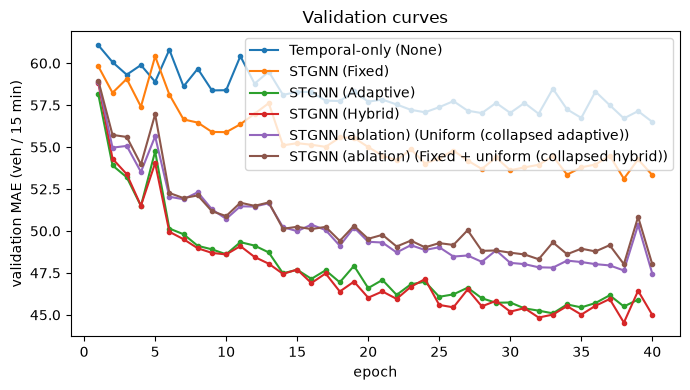

In [28]:
# %% ===================== Q6 CELL 1 (Q6a): comparison table =====================
RUNS = [("Temporal-only", "None", "temporal_only"), ("STGNN", "Fixed", "stgnn_fixed"),
        ("STGNN", "Adaptive", "stgnn_adaptive"), ("STGNN", "Hybrid", "stgnn_hybrid"),
        ("STGNN (ablation)", "Uniform (collapsed adaptive)", "stgnn_adaptive_wd"),
        ("STGNN (ablation)", "Fixed + uniform (collapsed hybrid)", "stgnn_hybrid_wd")]
R = {k: json.load(open(f"{OUT_DIR}/res_{k}.json")) for _, _, k in RUNS}
rows = []
for model_name, adj, k in RUNS:
    r = R[k]
    rows.append({"Model": model_name, "Adjacency": adj,
                 "Val MAE": r["val"]["MAE"], "Val RMSE": r["val"]["RMSE"],
                 "Test MAE": r["test"]["MAE"], "Test RMSE": r["test"]["RMSE"],
                 "Train time (s)": r["train_time_s"], "Epochs": r["epochs_run"], "Best ep": r["best_epoch"],
                 "s/epoch": r["train_time_s"] / r["epochs_run"], "Params": r["params"]})
table = pd.DataFrame(rows)
pd.set_option("display.width", 200)
print(table.round(2).to_string(index=False))
if "alpha" in R["stgnn_hybrid"]: print("learned hybrid alpha:", round(R["stgnn_hybrid"]["alpha"], 4))

hz = pd.DataFrame({f"{m} ({a})": [f"{mae:.2f} / {rmse:.2f}" for mae, rmse in zip(R[k]["test"]["MAE_h"], R[k]["test"]["RMSE_h"])]
                   for m, a, k in RUNS}, index=["+15 min", "+30 min", "+45 min", "+60 min"])
print("\nTest MAE / RMSE per horizon:\n", hz.to_string())
table.to_csv(f"{OUT_DIR}/results_table.csv", index=False); hz.to_csv(f"{OUT_DIR}/results_per_horizon.csv")

fig, ax = plt.subplots(figsize=(7, 4))
for m, a, k in RUNS:
    ax.plot([h["epoch"] for h in R[k]["history"]], [h["val_MAE"] for h in R[k]["history"]], marker=".", label=f"{m} ({a})")
ax.set_xlabel("epoch"); ax.set_ylabel("validation MAE (veh / 15 min)"); ax.legend(); ax.set_title("Validation curves")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/q6a_val_curves.png", dpi=200); plt.show()

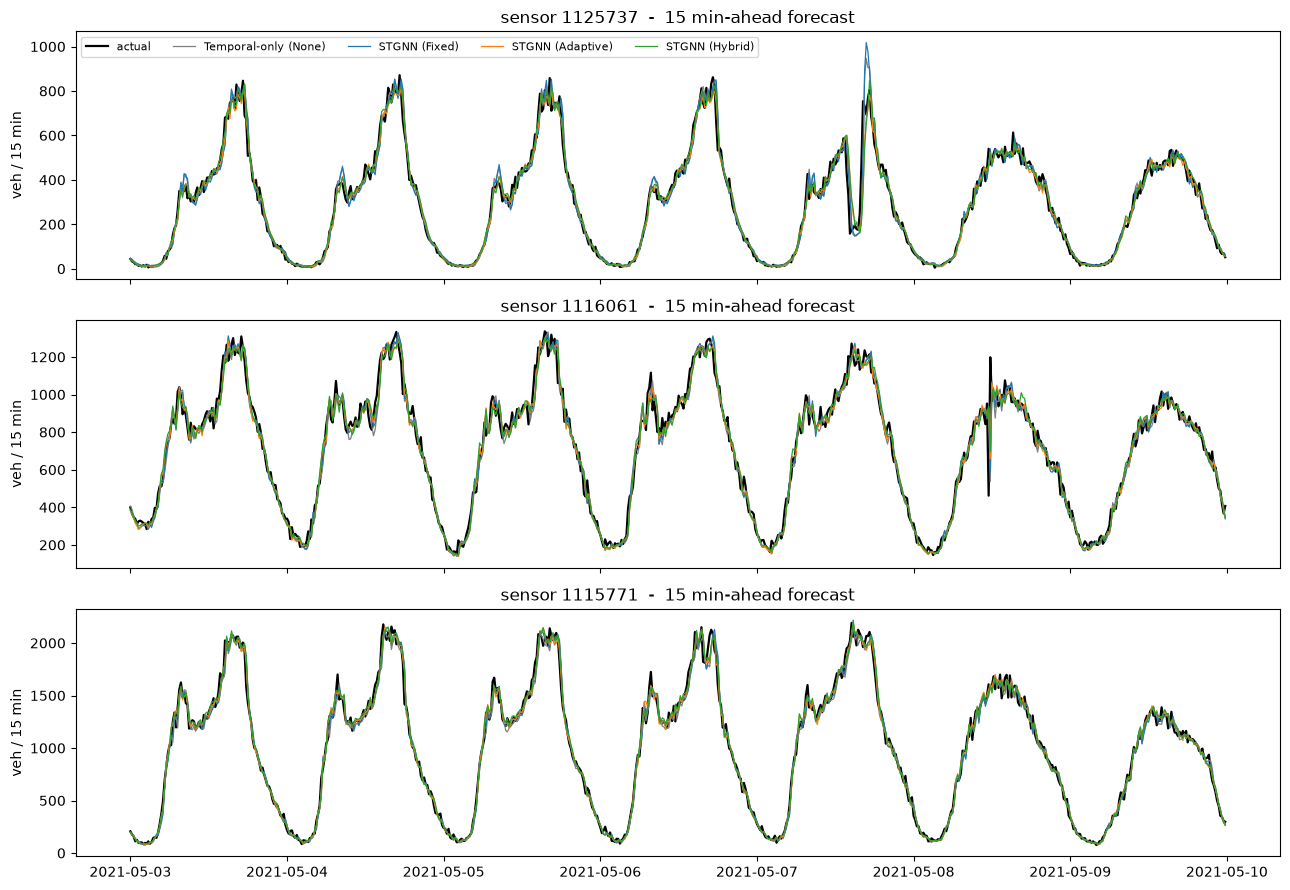

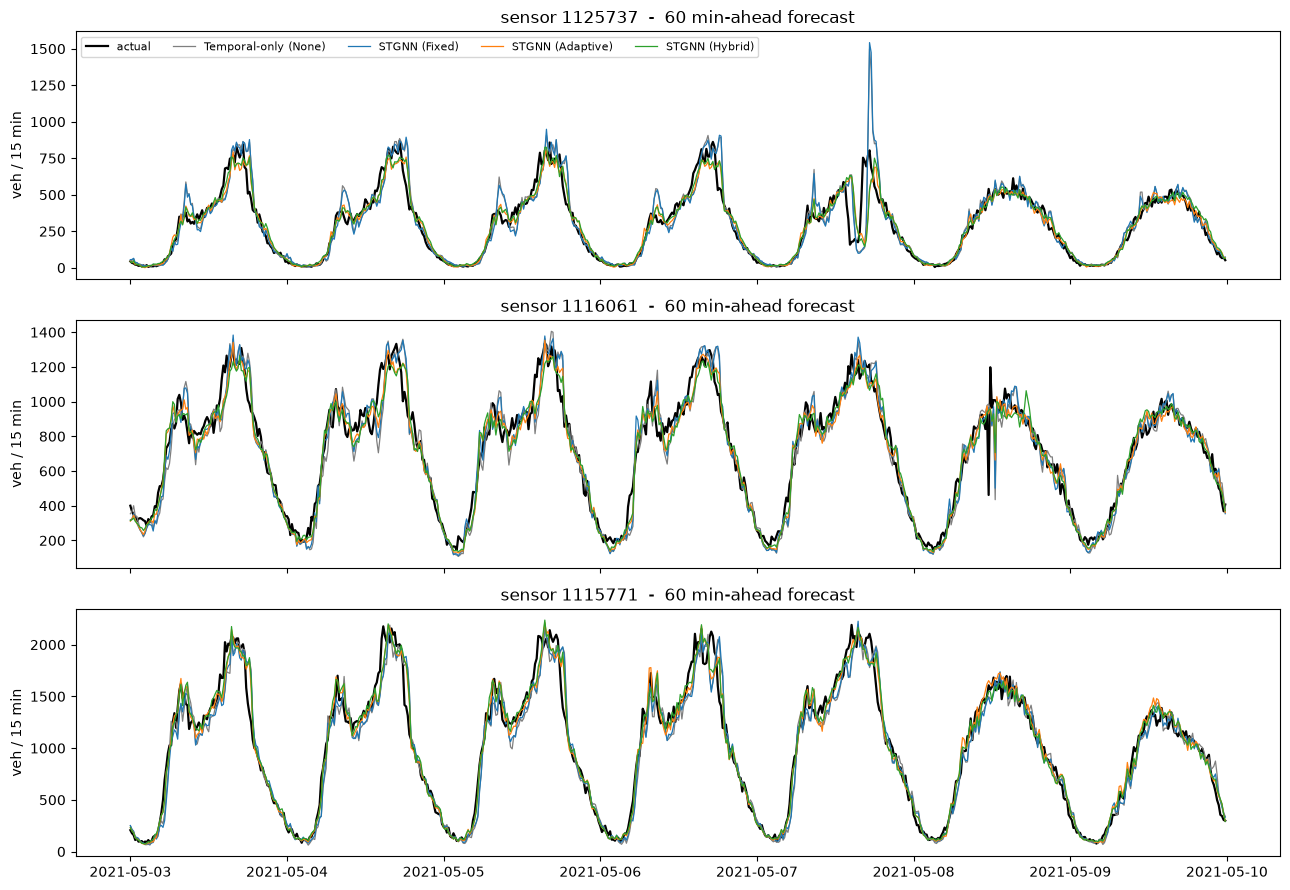

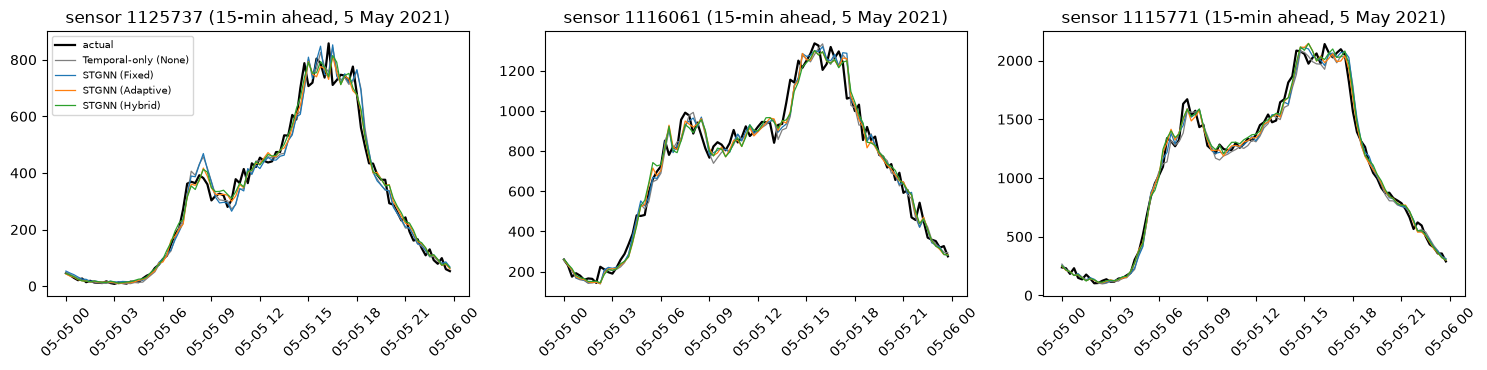

In [29]:
# %% ===================== Q6 CELL 2 (Q6a): predicted vs actual, 3 sensors, one test week =====================
P = {k: np.load(f"{OUT_DIR}/pred_{k}.npy") for _, _, k in RUNS}      # (n_test_windows, 4, 3)
t_test = idx["test"]
WEEK = ("2021-05-03", "2021-05-10")
for h, hname in [(0, "15 min"), (3, "60 min")]:
    fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True)
    target_t = t_test + h + 1                                          # time being predicted
    sel = (times[target_t] >= WEEK[0]) & (times[target_t] < WEEK[1])
    for a_i, (ax, s) in enumerate(zip(axes, PLOT_SENSORS)):
        tt = times[target_t[sel]]
        actual = np.where(M_np[target_t[sel], s], X_np[target_t[sel], s], np.nan)   # unobserved -> gap
        ax.plot(tt, actual, color="k", lw=1.6, label="actual")
        for (m, a, k), c in zip(RUNS, ["tab:grey", "tab:blue", "tab:orange", "tab:green"]):
            ax.plot(tt, P[k][sel, h, a_i], lw=.9, color=c, label=f"{m} ({a})")
        ax.set_title(f"sensor {ids[s]}  -  {hname}-ahead forecast"); ax.set_ylabel("veh / 15 min")
    axes[0].legend(ncol=5, fontsize=8)
    plt.tight_layout(); plt.savefig(f"{FIG_DIR}/q6a_pred_vs_actual_h{h+1}.png", dpi=200); plt.show()

# zoom on one day for readability
day = ("2021-05-05", "2021-05-06")
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
target_t = t_test + 1; sel = (times[target_t] >= day[0]) & (times[target_t] < day[1])
for a_i, (ax, s) in enumerate(zip(axes, PLOT_SENSORS)):
    tt = times[target_t[sel]]
    ax.plot(tt, np.where(M_np[target_t[sel], s], X_np[target_t[sel], s], np.nan), "k", lw=1.6, label="actual")
    for (m, a, k), c in zip(RUNS, ["tab:grey", "tab:blue", "tab:orange", "tab:green"]):
        ax.plot(tt, P[k][sel, 0, a_i], lw=.9, color=c, label=f"{m} ({a})")
    ax.set_title(f"sensor {ids[s]} (15-min ahead, 5 May 2021)"); ax.tick_params(axis="x", rotation=45)
axes[0].legend(fontsize=7)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/q6a_pred_vs_actual_day.png", dpi=200); plt.show()

adaptive row sums ~1: True
effective #neighbours per row exp(entropy): median 21.3 (uniform would be 716)
largest weight per row: median 0.173; self-weight median 0.0000


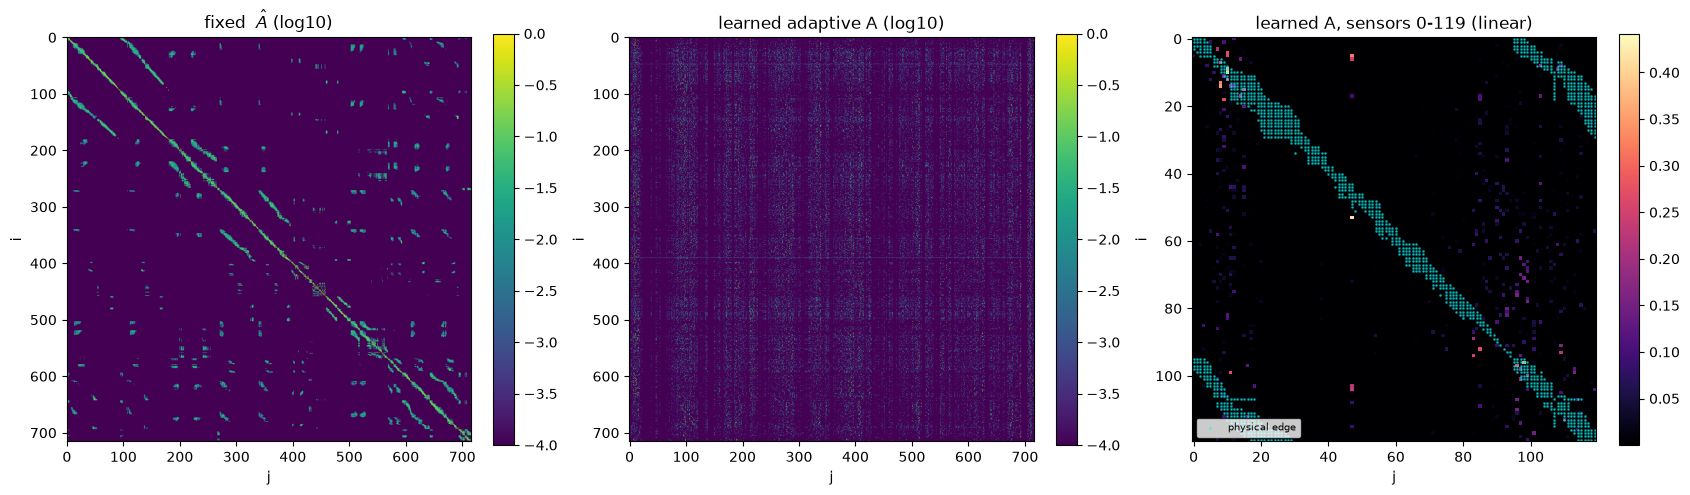

In [30]:
# %% ===================== Q6 CELL 3 (Q5b + Q6b): learned graph - visualisation =====================
from scipy.sparse.csgraph import shortest_path
from scipy.stats import spearmanr

A_ad = np.load(f"{OUT_DIR}/Aadapt_stgnn_adaptive.npy")
A_fx = A_hat_fixed
print("adaptive row sums ~1:", np.allclose(A_ad.sum(1), 1, atol=1e-4))
ent = -(A_ad * np.log(A_ad + 1e-12)).sum(1)
print(f"effective #neighbours per row exp(entropy): median {np.median(np.exp(ent)):.1f} (uniform would be {N})")
print(f"largest weight per row: median {np.median(A_ad.max(1)):.3f}; self-weight median {np.median(np.diag(A_ad)):.4f}")

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
im0 = axes[0].imshow(np.log10(A_fx + 1e-6), cmap="viridis", vmin=-4, vmax=0); axes[0].set_title("fixed  $\\hat A$ (log10)")
im1 = axes[1].imshow(np.log10(A_ad + 1e-6), cmap="viridis", vmin=-4, vmax=0); axes[1].set_title("learned adaptive A (log10)")
z = slice(0, 120)
im2 = axes[2].imshow(A_ad[z, z], cmap="magma"); axes[2].set_title("learned A, sensors 0-119 (linear)")
yy, xx = np.nonzero(A_np[z, z]); axes[2].scatter(xx, yy, s=1, c="cyan", alpha=.5, label="physical edge")
axes[2].legend(loc="lower left", fontsize=7)
for ax, im in zip(axes, [im0, im1, im2]): fig.colorbar(im, ax=ax, fraction=.046); ax.set_xlabel("j"); ax.set_ylabel("i")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/q5b_learned_adjacency.png", dpi=200); plt.show()

                              graph  edges  in physical graph (%)  median km  1-hop %  2-hop %  3+ hop %  unreachable %  mean flow corr
       learned adaptive, top-10/row   7160                  4.846     22.639    4.846    6.746    82.291          6.117           0.875
adaptive part of hybrid, top-10/row   7160                  4.804     23.276    4.804    6.620    81.564          7.011           0.871
    physical road graph (all edges)  17319                100.000      2.371  100.000    0.000     0.000          0.000           0.861
                       random pairs   7152                  4.167     22.694    4.167    5.789    86.395          3.649           0.843
(physical-graph density = 4.11% -> expected overlap for random edges)
Spearman(fixed weight, learned weight) over physical edges: 0.002 (p=8.1e-01)
mean learned weight on physical edges 0.00168 vs non-edges 0.00138

20 strongest learned connections:
       i       j  weight  physical edge  hops     km  flow corr
112241

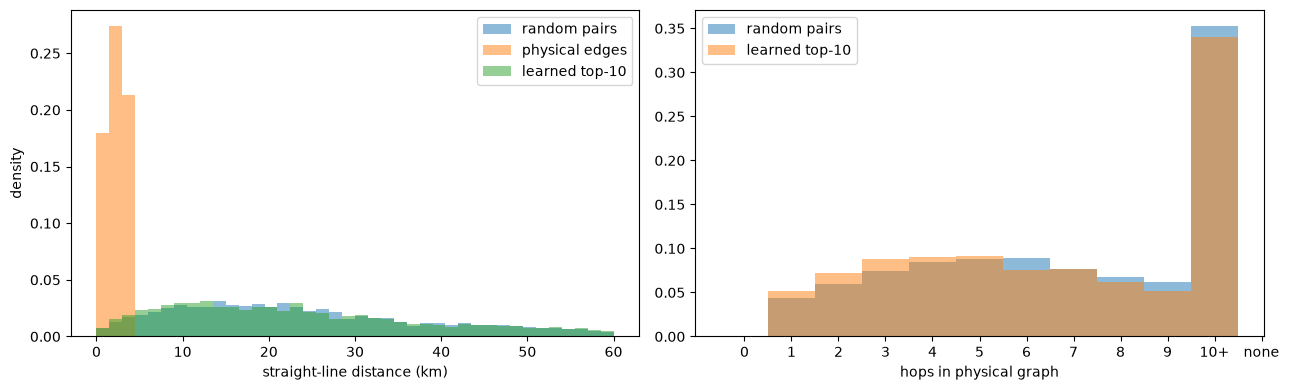

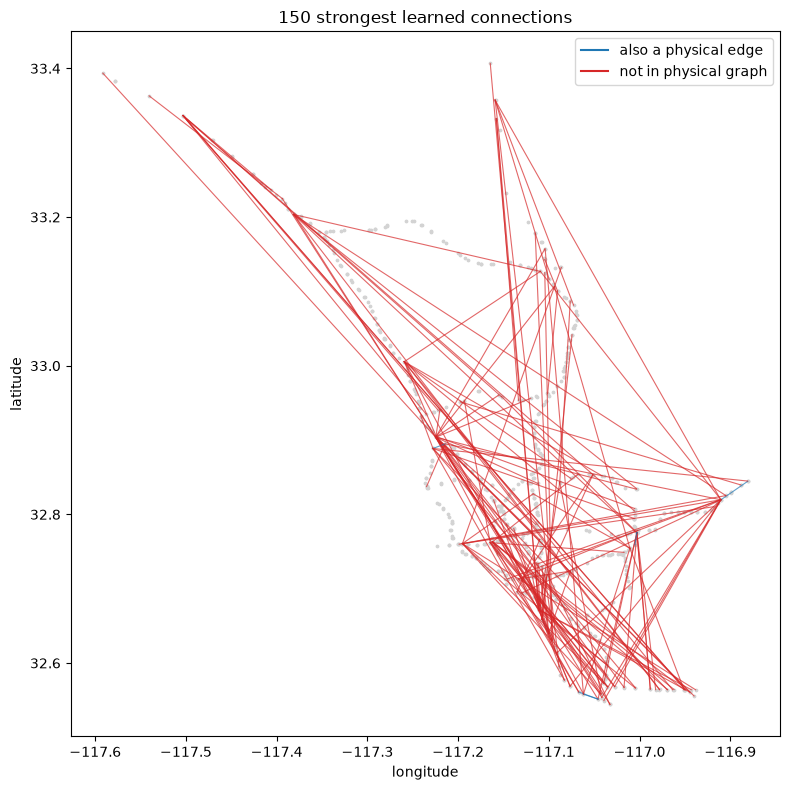

In [31]:
# %% ===================== Q6 CELL 4 (Q6b): learned vs physical graph - quantitative =====================
def haversine(i, j):
    la1, lo1, la2, lo2 = map(np.radians, (lat[i], lng[i], lat[j], lng[j]))
    a = np.sin((la2 - la1) / 2)**2 + np.cos(la1) * np.cos(la2) * np.sin((lo2 - lo1) / 2)**2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

tr = split_masks["train"]
Xtr, Mtr = X_np[tr], M_np[tr]
def corr_pairs(pairs, min_obs=1000):                                   # flow correlation on TRAIN data only
    out = []
    for i, j in pairs:
        m = Mtr[:, i] & Mtr[:, j]
        out.append(np.corrcoef(Xtr[m, i], Xtr[m, j])[0, 1] if m.sum() >= min_obs else np.nan)
    return np.array(out)

phys = (A_np != 0) | (A_np.T != 0); np.fill_diagonal(phys, False)       # physical edge in either direction
hops = shortest_path((A_np != 0).astype(float), directed=False, unweighted=True)
density = phys.sum() / (N * (N - 1))
rng = np.random.default_rng(SEED)

def pair_stats(I, J, name):
    h = hops[I, J]
    sub = np.random.default_rng(SEED).choice(len(I), min(1500, len(I)), replace=False)   # correlation on a subsample
    return {"graph": name, "edges": len(I), "in physical graph (%)": phys[I, J].mean() * 100,
            "median km": np.median(haversine(I, J)), "1-hop %": (h == 1).mean() * 100, "2-hop %": (h == 2).mean() * 100,
            "3+ hop %": ((h >= 3) & np.isfinite(h)).mean() * 100, "unreachable %": (~np.isfinite(h)).mean() * 100,
            "mean flow corr": np.nanmean(corr_pairs(list(zip(I[sub], J[sub]))))}

def topk_pairs(Aw, K=10):
    Aw = Aw.copy(); np.fill_diagonal(Aw, -np.inf)
    return np.repeat(np.arange(N), K), np.argsort(-Aw, axis=1)[:, :K].ravel()

A_hyb_ad = np.load(f"{OUT_DIR}/Aadapt_stgnn_hybrid.npy")
I_ad, J_ad = topk_pairs(A_ad); I_hy, J_hy = topk_pairs(A_hyb_ad)
ii, jj = np.nonzero(A_np); off_d = ii != jj
I_r = rng.integers(0, N, 7160); J_r = rng.integers(0, N, 7160); keep = I_r != J_r; I_r, J_r = I_r[keep], J_r[keep]
h_r = hops[I_r, J_r]
S = pd.DataFrame([pair_stats(I_ad, J_ad, "learned adaptive, top-10/row"),
                  pair_stats(I_hy, J_hy, "adaptive part of hybrid, top-10/row"),
                  pair_stats(ii[off_d], jj[off_d], "physical road graph (all edges)"),
                  pair_stats(I_r, J_r, "random pairs")])
print(S.round(3).to_string(index=False)); S.to_csv(f"{OUT_DIR}/q6b_graph_stats.csv", index=False)
print(f"(physical-graph density = {density*100:.2f}% -> expected overlap for random edges)")

rho, pv = spearmanr(A_np[ii[off_d], jj[off_d]], A_ad[ii[off_d], jj[off_d]])
print(f"Spearman(fixed weight, learned weight) over physical edges: {rho:.3f} (p={pv:.1e})")
print(f"mean learned weight on physical edges {A_ad[phys].mean():.5f} vs non-edges {A_ad[~phys & ~np.eye(N, dtype=bool)].mean():.5f}")

Aw = A_ad.copy(); np.fill_diagonal(Aw, 0)
flat = np.argsort(-Aw.ravel())[:20]
top20 = pd.DataFrame({"i": ids[flat // N], "j": ids[flat % N], "weight": Aw.ravel()[flat],
                      "physical edge": phys.ravel()[flat], "hops": hops.ravel()[flat],
                      "km": haversine(flat // N, flat % N), "flow corr": corr_pairs(list(zip(flat // N, flat % N)))})
print("\n20 strongest learned connections:\n", top20.round(3).to_string(index=False))
top20.to_csv(f"{OUT_DIR}/q6b_top20_learned.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
bins = np.linspace(0, 60, 41)
axes[0].hist(haversine(I_r, J_r), bins, alpha=.5, density=True, label="random pairs")
axes[0].hist(haversine(ii[off_d], jj[off_d]), bins, alpha=.5, density=True, label="physical edges")
axes[0].hist(haversine(I_ad, J_ad), bins, alpha=.5, density=True, label="learned top-10")
axes[0].set_xlabel("straight-line distance (km)"); axes[0].set_ylabel("density"); axes[0].legend()
hb = np.arange(0, 12) - .5
for (lab, h) in [("random pairs", h_r), ("learned top-10", hops[I_ad, J_ad])]:
    axes[1].hist(np.where(np.isfinite(h), np.minimum(h, 10), 11), hb, alpha=.5, density=True, label=lab)
axes[1].set_xticks(range(0, 12)); axes[1].set_xticklabels([str(k) for k in range(10)] + ["10+", "none"])
axes[1].set_xlabel("hops in physical graph"); axes[1].legend()
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/q6b_distance_hops.png", dpi=200); plt.show()

# map: strongest 150 learned edges, coloured by whether they exist physically
fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(lng, lat, s=3, c="lightgrey")
for f_ in np.argsort(-Aw.ravel())[:150]:
    i, j = divmod(f_, N)
    ax.plot([lng[i], lng[j]], [lat[i], lat[j]], lw=.8, alpha=.7, c="tab:blue" if phys[i, j] else "tab:red")
ax.plot([], [], c="tab:blue", label="also a physical edge"); ax.plot([], [], c="tab:red", label="not in physical graph")
ax.legend(); ax.set_title("150 strongest learned connections"); ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/q6b_learned_edges_map.png", dpi=200); plt.show()

sensors with <5% observed training data: 19 (2.7% of nodes)

adaptive: attention mass on dead sensors per row: median 13.7%, mean 16.3%  (uniform share would be 2.7%)
  10 most-attended sensors (ID, total in-weight, % observed in 2020):
    1118458   11.17     0.0%
    1123069    8.78     0.0%
    1115528    8.61     0.0%
    1126722    8.56   100.0%
    1123087    8.44     0.0%
    1119653    8.32     0.0%
    1108299    8.18     0.0%
    1118365    7.70   100.0%
    1118450    7.53   100.0%
    1115420    7.45     0.0%
  share of all attention taken by the 10 most-attended sensors: 11.8%

adaptive part of hybrid: attention mass on dead sensors per row: median 10.1%, mean 13.1%  (uniform share would be 2.7%)
  10 most-attended sensors (ID, total in-weight, % observed in 2020):
    1126722   10.52   100.0%
    1123064    8.59     0.0%
    1123276    8.34   100.0%
    1118450    7.60   100.0%
    1115528    7.14     0.0%
    1108505    6.89   100.0%
    1108558    6.73   100.0%
    1108

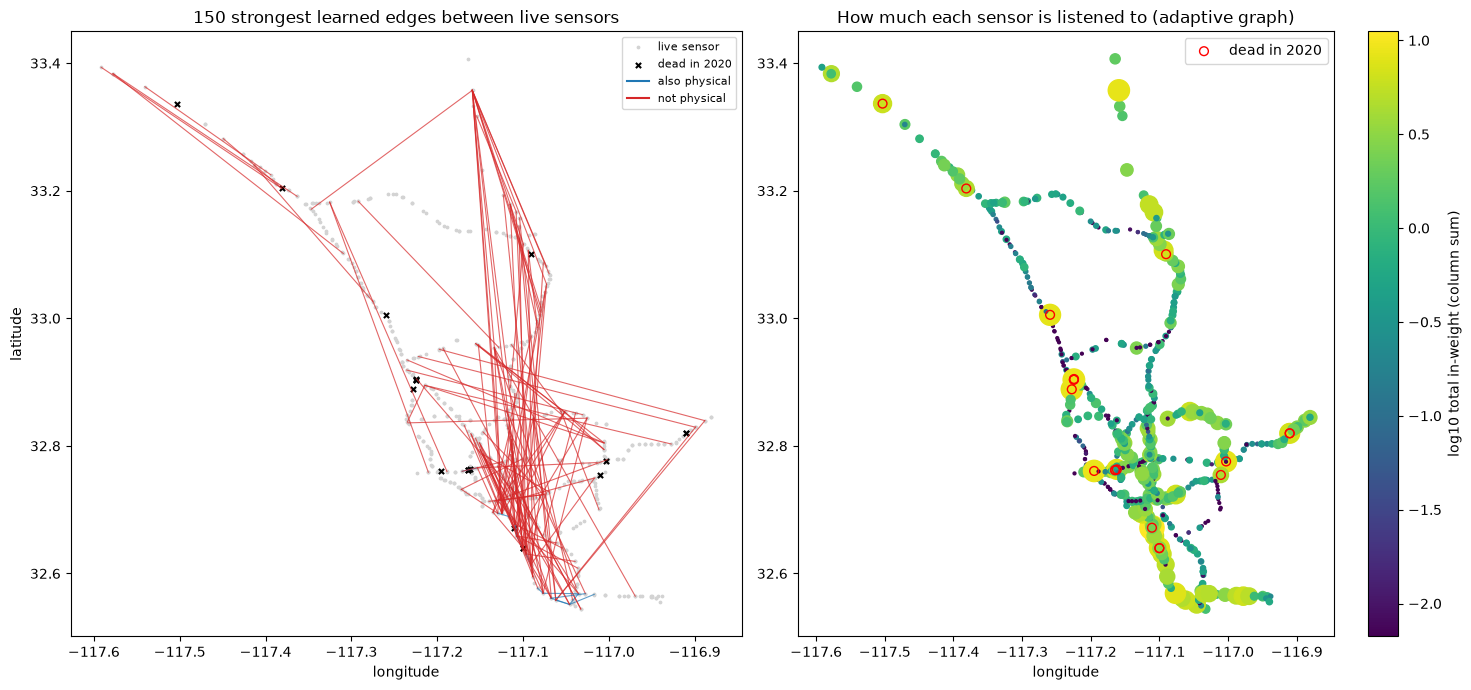

In [32]:
# %% ===================== Q6 CELL 5 (Q6b): where does the learned attention go? + live-sensor analysis =====================
import warnings
tr_obs = M_np[split_masks["train"]].mean(0)               # fraction of 2020 observed per sensor
dead = tr_obs < 0.05                                       # (almost) never observed in training -> constant imputed input
live = ~dead
print(f"sensors with <5% observed training data: {dead.sum()} ({dead.mean()*100:.1f}% of nodes)")
for name, Aw in [("adaptive", A_ad), ("adaptive part of hybrid", A_hyb_ad)]:
    mass = Aw[:, dead].sum(1)
    print(f"\n{name}: attention mass on dead sensors per row: median {np.median(mass)*100:.1f}%, "
          f"mean {mass.mean()*100:.1f}%  (uniform share would be {dead.mean()*100:.1f}%)")
    in_strength = Aw.sum(0)                                # column sums = how much the network listens to j
    top_src = np.argsort(-in_strength)[:10]
    print("  10 most-attended sensors (ID, total in-weight, % observed in 2020):")
    for j in top_src: print(f"    {ids[j]}  {in_strength[j]:6.2f}   {tr_obs[j]*100:5.1f}%")
    print(f"  share of all attention taken by the 10 most-attended sensors: {in_strength[top_src].sum()/N*100:.1f}%")

# de-seasonalised (residual) flows: subtract each sensor's mean time-of-week profile (training data only)
tw = times[split_masks["train"]]
tow = (tw.dayofweek * 96 + tw.hour * 4 + tw.minute // 15).values
Xm = np.where(Mtr, Xtr, np.nan)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    prof = np.stack([np.nanmean(Xm[tow == k], 0) for k in range(672)])
Rtr = Xtr - prof[tow]

def corr_resid(pairs, min_obs=1000):
    out = []
    for i, j in pairs:
        m = Mtr[:, i] & Mtr[:, j] & np.isfinite(Rtr[:, i]) & np.isfinite(Rtr[:, j])
        out.append(np.corrcoef(Rtr[m, i], Rtr[m, j])[0, 1] if m.sum() >= min_obs else np.nan)
    return np.array(out)

def topk_live(Aw, K=10):
    Aw = Aw.copy(); np.fill_diagonal(Aw, -np.inf); Aw[:, dead] = -np.inf
    rows = np.where(live)[0]
    return np.repeat(rows, K), np.argsort(-Aw[rows], 1)[:, :K].ravel()

def stats_live(I, J, name):
    sub = np.random.default_rng(SEED).choice(len(I), min(1500, len(I)), replace=False)
    pairs = list(zip(I[sub], J[sub])); h = hops[I, J]
    return {"graph": name, "edges": len(I), "in physical (%)": phys[I, J].mean() * 100,
            "median km": np.median(haversine(I, J)), "<=2 hops (%)": (h <= 2).mean() * 100,
            "unreachable (%)": (~np.isfinite(h)).mean() * 100,
            "raw corr": np.nanmean(corr_pairs(pairs)), "residual corr": np.nanmean(corr_resid(pairs))}

I_l, J_l = topk_live(A_ad); I_lh, J_lh = topk_live(A_hyb_ad)
pe = live[ii] & live[jj] & off_d
rr = np.random.default_rng(SEED); lv = np.where(live)[0]
I_rl = rr.choice(lv, 7000); J_rl = rr.choice(lv, 7000); k_ = I_rl != J_rl; I_rl, J_rl = I_rl[k_], J_rl[k_]
SL = pd.DataFrame([stats_live(I_l, J_l, "adaptive top-10 (live sensors)"),
                   stats_live(I_lh, J_lh, "hybrid-adaptive top-10 (live)"),
                   stats_live(ii[pe], jj[pe], "physical edges (live)"),
                   stats_live(I_rl, J_rl, "random pairs (live)")])
print("\n", SL.round(3).to_string(index=False)); SL.to_csv(f"{OUT_DIR}/q6b_graph_stats_live.csv", index=False)

Awl = A_ad.copy(); np.fill_diagonal(Awl, 0); Awl[:, dead] = 0; Awl[dead, :] = 0
flat = np.argsort(-Awl.ravel())[:20]; fi, fj = flat // N, flat % N
top20l = pd.DataFrame({"i": ids[fi], "j": ids[fj], "weight": Awl.ravel()[flat], "physical": phys[fi, fj],
                       "hops": hops[fi, fj], "km": haversine(fi, fj),
                       "raw corr": corr_pairs(list(zip(fi, fj))), "residual corr": corr_resid(list(zip(fi, fj)))})
print("\n20 strongest learned connections between LIVE sensors:\n", top20l.round(3).to_string(index=False))
top20l.to_csv(f"{OUT_DIR}/q6b_top20_learned_live.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
ax = axes[0]
ax.scatter(lng[live], lat[live], s=3, c="lightgrey", label="live sensor")
ax.scatter(lng[dead], lat[dead], s=14, c="k", marker="x", label="dead in 2020")
for f_ in np.argsort(-Awl.ravel())[:150]:
    i, j = divmod(f_, N)
    ax.plot([lng[i], lng[j]], [lat[i], lat[j]], lw=.8, alpha=.7, c="tab:blue" if phys[i, j] else "tab:red")
ax.plot([], [], c="tab:blue", label="also physical"); ax.plot([], [], c="tab:red", label="not physical")
ax.legend(fontsize=8); ax.set_title("150 strongest learned edges between live sensors")
ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
ax = axes[1]
ins = A_ad.sum(0)
sc = ax.scatter(lng, lat, s=4 + 30 * ins / ins.max() * 10, c=np.log10(ins), cmap="viridis")
ax.scatter(lng[dead], lat[dead], s=40, facecolors="none", edgecolors="r", label="dead in 2020")
fig.colorbar(sc, ax=ax, label="log10 total in-weight (column sum)")
ax.legend(); ax.set_title("How much each sensor is listened to (adaptive graph)")
ax.set_xlabel("longitude")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/q6b_attention_live.png", dpi=200); plt.show()